In [57]:
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

from astropy.io import fits
from glob import glob
#from scipy.optimize import curve_fit

#import photutils
from photutils import aperture_photometry, CircularAperture, CircularAnnulus

ModuleNotFoundError: No module named 'photutils'

# Set-up

## Importing 

### Science Camera Images

#### Data for Section 10.2 "First Observation"
Files saved starting with: "obs1_*.fits"
- All observations taken with t_exposure = 30 secs
- default filter = R, otherwise the filter used is stated

In [58]:
filepath = "Data/" # directory data files are in, can be altered 
filepaths_obs1 = glob(filepath+"obs1_*.fits")
filepaths_obs1

['Data\\obs1_star1_app1_30s.fits',
 'Data\\obs1_star1_app2_30s.fits',
 'Data\\obs1_star1_app3_30s.fits',
 'Data\\obs1_star1_app4_30s_B.fits',
 'Data\\obs1_star1_app4_30s_C.fits',
 'Data\\obs1_star1_app4_30s_G.fits',
 'Data\\obs1_star1_app4_30s_R.fits']

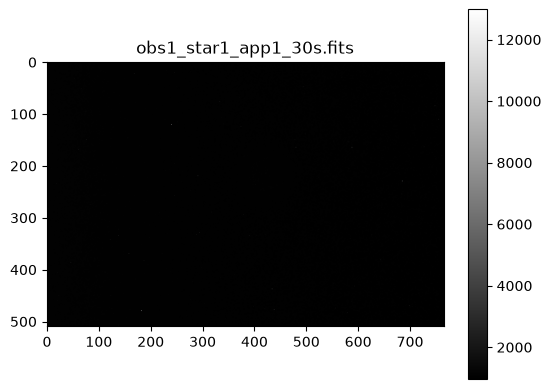

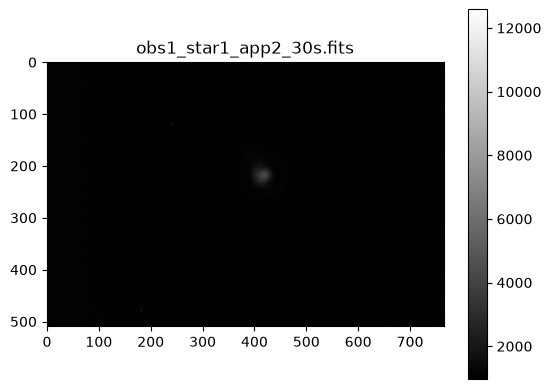

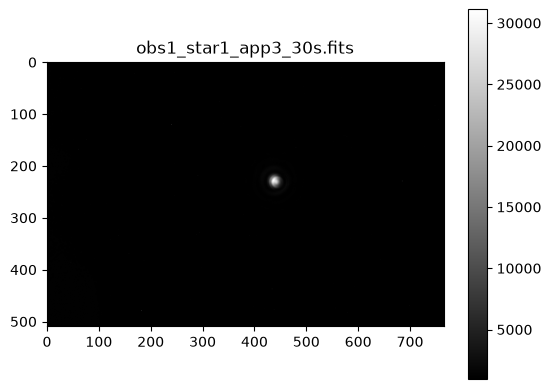

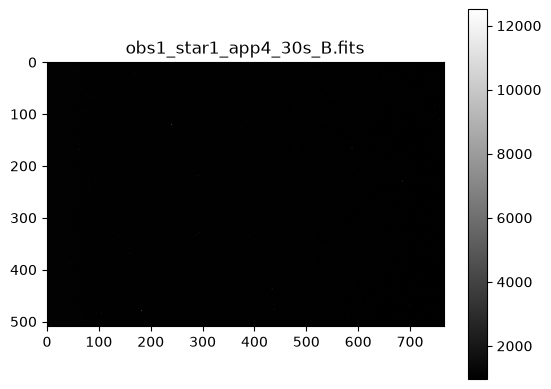

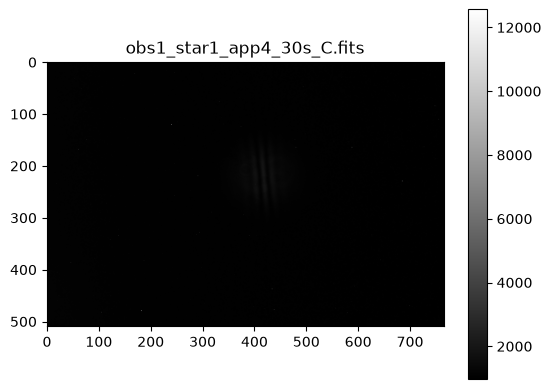

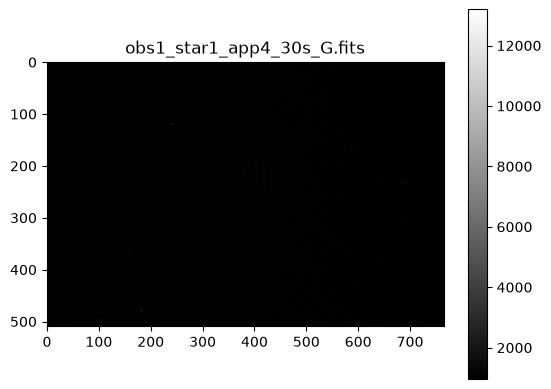

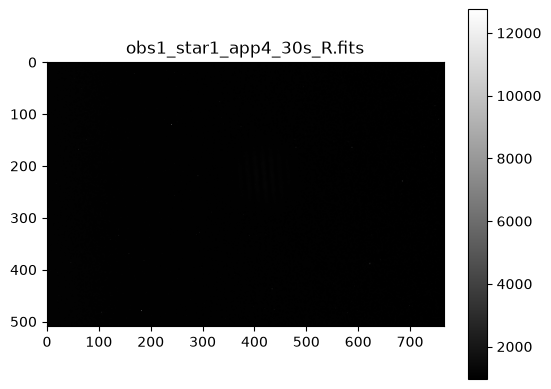

In [3]:
# open image files, check, & save
obs1_array = []
for img in filepaths_obs1:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    #plt.close()
    obs1_array.append(file)

### [Bias / Flats / Darks] for Reducing the Science Camera Images

<u>Need to take:<u>
- bias images
    - taken with closed shutter & ~ 0 second exposure time
    - should take *multiple* bias images 
- flats [images]
    - to take a flat field image, must uniformly illuminate the CCD (& not over-exposure) => could uniformly illuminate white screen/sheet of paper?
    - each filter should have its own set of flats
    - exposure time => 
- dark images
    - taken with closed shutter. Exposure time can vary => could match to observation exposure time. 



Will take:
- [multiple] dark images w/30 second exposure
    - (our dark images will double as our bias images) 
- [ multiple] flat field images w/30 second exposure

In [59]:
filepaths_darks = glob(filepath+"dark_*.fits")
filepaths_darks

['Data\\dark_30s_1.fits',
 'Data\\dark_30s_10.fits',
 'Data\\dark_30s_2.fits',
 'Data\\dark_30s_3.fits',
 'Data\\dark_30s_4.fits',
 'Data\\dark_30s_5.fits',
 'Data\\dark_30s_6.fits',
 'Data\\dark_30s_7.fits',
 'Data\\dark_30s_8.fits',
 'Data\\dark_30s_9.fits']

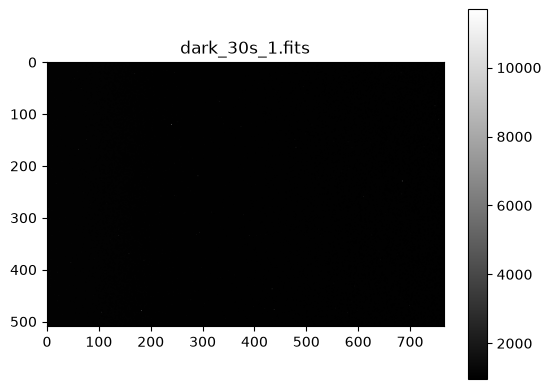

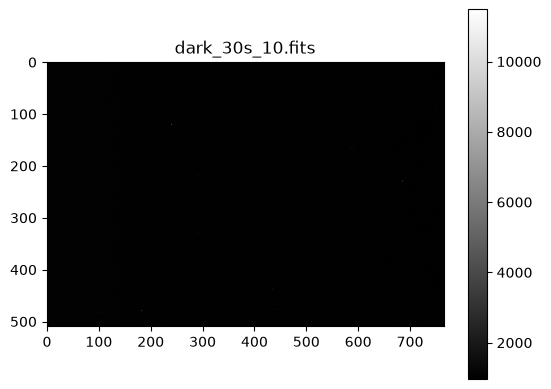

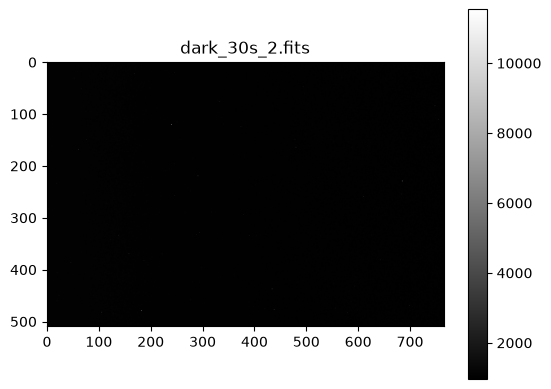

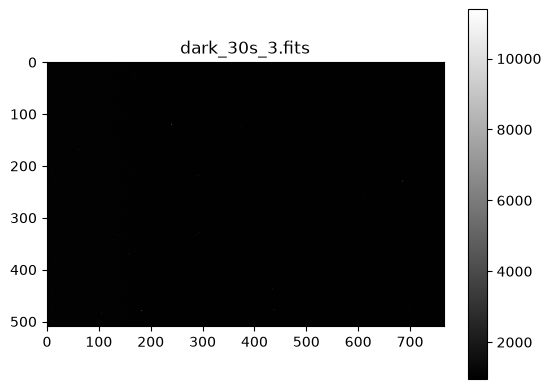

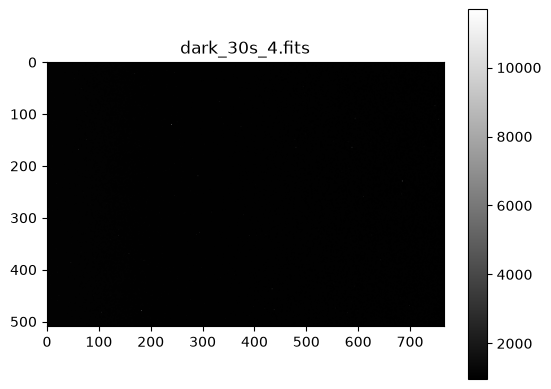

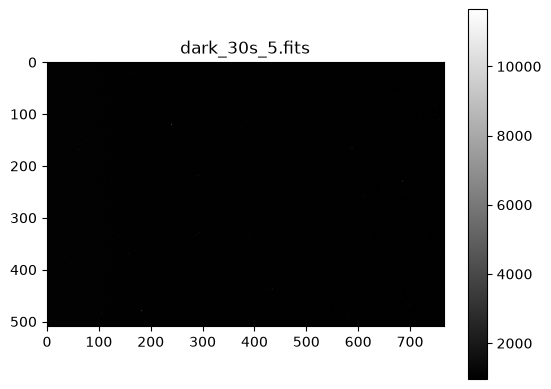

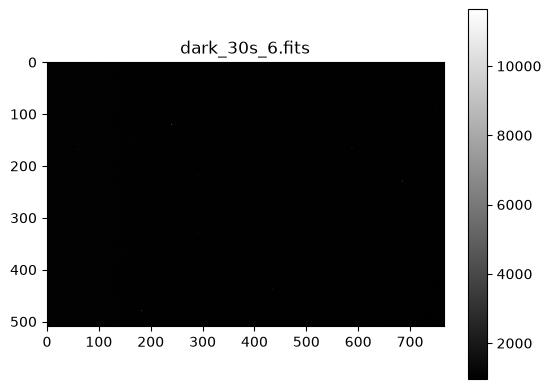

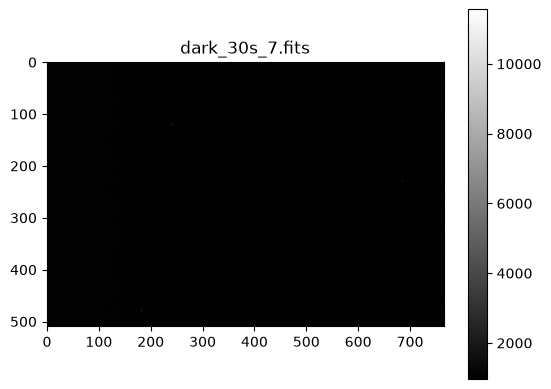

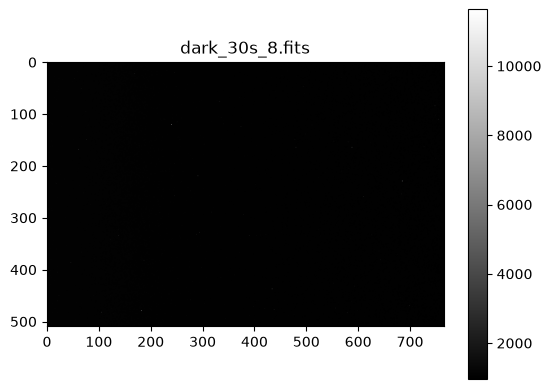

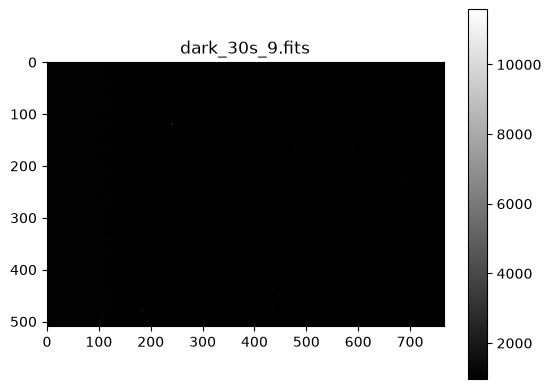

In [61]:
# open image files, check, & save
darks_array = []
for img in filepaths_darks:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    darks_array.append(file)

In [60]:
filepaths_flats = glob(filepath+"flat_*.fits")
filepaths_flats

['Data\\flat_30s_1.fits',
 'Data\\flat_30s_10.fits',
 'Data\\flat_30s_2.fits',
 'Data\\flat_30s_3.fits',
 'Data\\flat_30s_4.fits',
 'Data\\flat_30s_5.fits',
 'Data\\flat_30s_6.fits',
 'Data\\flat_30s_7.fits',
 'Data\\flat_30s_8.fits',
 'Data\\flat_30s_9.fits']

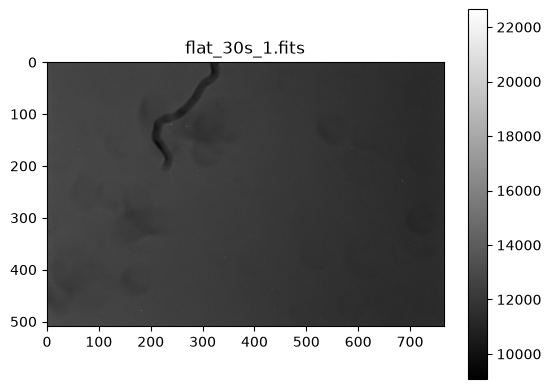

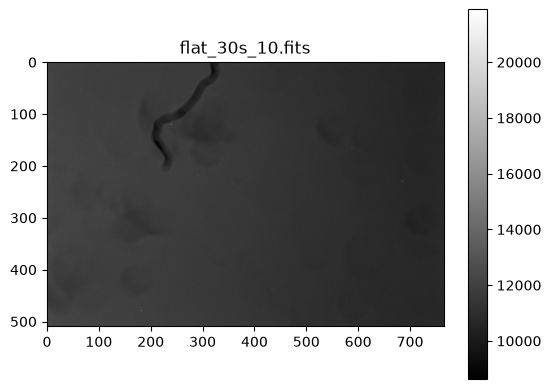

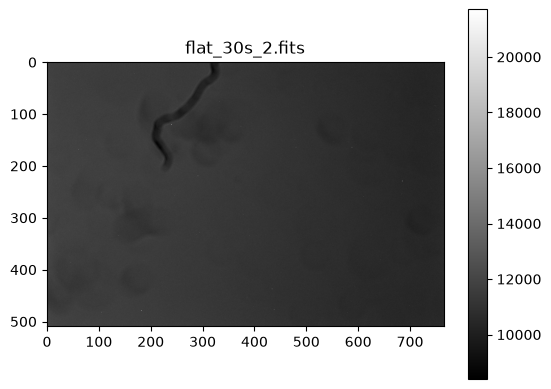

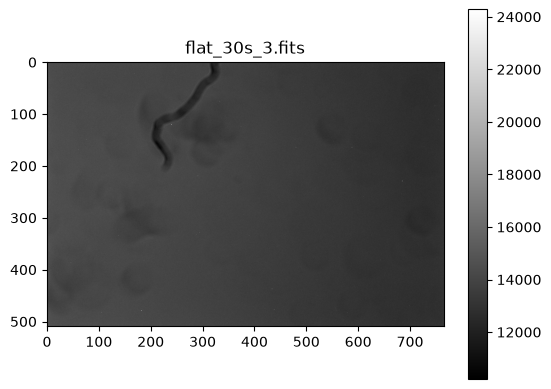

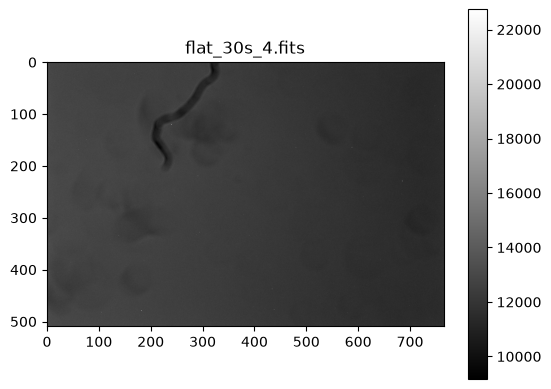

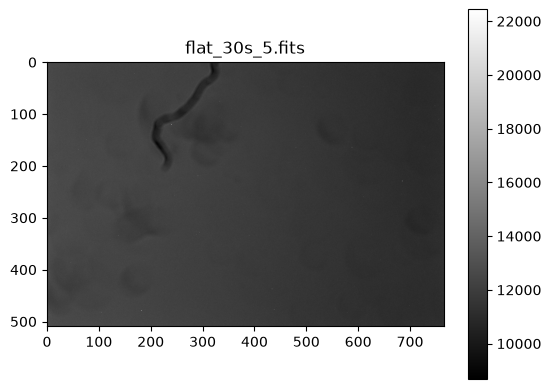

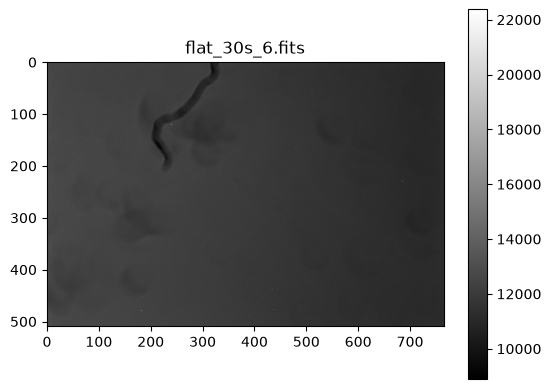

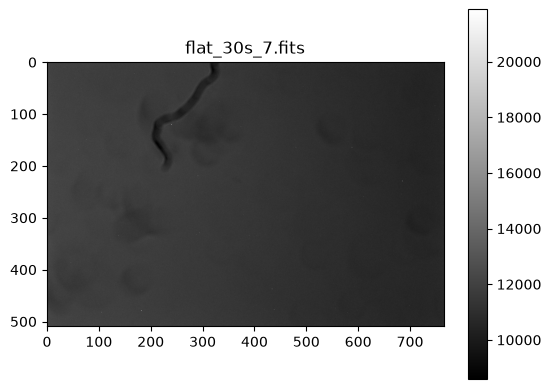

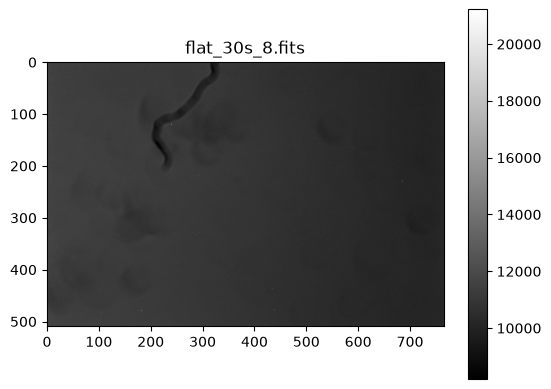

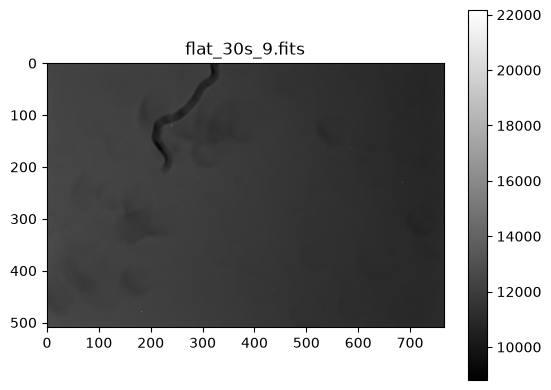

In [62]:
# open image files, check, & save
flats_array = []
for img in filepaths_flats:
    file = fits.open(img)
    file = file[0].data
    file = file.astype('int32')
    plt.figure()
    plt.imshow(file, cmap='gray')
    plt.colorbar()
    plt.title(img[5:])
    flats_array.append(file) # in images, can see thread/fibre that now seems to be on the telescope lens 
                                        # (may have to crop images post-reduction / be careful when getting counts

## Reduce the FITS files [calibrating the images]

<u>Processing:<u>
- [Throughout this, we're using the darks as a combination of biases & darks [*all images* taken for 30s exposure)
- Take mean of multiple bias [dark] images to get the 'masterbias' [masterdark]
- Subtract masterbias [masterdark] from *each* of the flats,
    - ~also subtract the masterdark? [exposure time = important ...]~
    - THEN combine & normalise (by dividing by the average pixel value in the centre of the array/the "field of view")
- reduced science image = $\frac{[\text{science image - masterflat}]}{\text{normalised masterflat}}$

In [ ]:
# create masterdark / masterbias
master_dark = np.mean(darks_array, axis=0)
newHeader_dark = fits.PrimaryHDU(master_dark)
newHeader_dark.writeto(filepath)
    #"C:/Users/nowar/Documents/GitHub/3rd-Year-Labs/Exp 2 CCDs & Spectroscopy/data/master_dark.fits")

## Setting up common variables

In [4]:
# "spectral band [for lamp used throughout] = 630 ± 50 nm
lamp_lambda=0.63 # wavelength of the lamp used in micrometre [mu m]
err_lamp_lambda=0.05 # uncertainty on the wavelength of the lamp used in micrometre [mu m]


# Section 10.2 "First Observations" Data Analysis

In [5]:
# FITS files are saved in obs1_array, with the filenames available from filepaths_obs1 [6:]
for filename in filepaths_obs1:
    print(filename[5:])

obs1_star1_app1_30s.fits
obs1_star1_app2_30s.fits
obs1_star1_app3_30s.fits
obs1_star1_app4_30s_B.fits
obs1_star1_app4_30s_C.fits
obs1_star1_app4_30s_G.fits
obs1_star1_app4_30s_R.fits


In [32]:
img_obs1_star1_a = obs1_array[2] # apperture mask = at position 3 = 5mm 
img_obs1_star1_b = obs1_array[0] # apperture mask = at position 1 = 1mm 
img_obs1_star1_c = obs1_array[1] # apperture mask = at position 2 = 2mm 

img_obs1_binary_R = obs1_array[6] # aperture mask @ position 4, filter = R 
img_obs1_binary_B = obs1_array[3] # aperture mask @ position 4, filter = B
img_obs1_binary_C = obs1_array[4] # aperture mask @ position 4, filter = C
img_obs1_binary_G = obs1_array[5] # aperture mask @ position 4, filter = G

## Task 2.1

- Lamp cover set to the single 'star' [position 1, Table 1 in manual]
- Telescope aperture mask set to [per Table 2 in manual]:
    - a) position 3 / 1 5mm-diameter aperture [=0.5cm = 0.005m]
    - b) position 1 / 1 1mm-diameter aperture [0.1cm = 0.001m]
    - c) position 2 / 1 3mm-diameter aperture [0.3cm = 0.003m]
    
For each of the images [a,b,c] [all should show an ~ Airy disk, per Fig12a in manual]:
- <b>Compute</b> the <u>angular radius</u> of the <u>Airy disk</u> (maximum to 1st dark ring)
    - for the given parameters "as discussed in Sect. 6.1"
        - "the 1st minimum of the PSF [Point Spread Function] (which produces an Airy disk) = @ $\alpha_{min} = 1.22 \frac{\lambda}{D}$ (or $\alpha_{min}/mas = 252 \frac{\lambda / \mu m}{D / m} $), with:
            - $\alpha$ in milli-arcsec [mas],
            - observing wavelength $\lambda$ in $\mu m$,
            - & the telescope diameter $D$ in $m$
        - [& the 1st minimum of the Airy pattern = the 1st dark ring in the image]
    - <b> & Compare</b> to the <u>diameter</u> in the image
        - => can measure the image coords of the maximum & the 1st dark ring <b>by</b> moving the cursor to the position & noting the pixel coordinate [presumably in SAO Image DS9 => easier if the images = reduced...]
        - pixel scale = 1.77 arcsec/pixel
        - spectral band = 630nm $\pm$ 50nm (=> assume can take as $\lambda$ => = $0.63 \pm \ 0.05\mu m$)
        - per manual [check!!], telescope has a diameter of 104mm = 10.4cm = 0.104m BUT have the __aperture mask__ in front, so using those values
            - not given uncertainty on aperture diameters => could just take as no uncertainty 

In [6]:
task2_1_apertures = 1e-3*np.array([5, 1, 3]) # multiplied by 1/1000 = 1e-3 to convert from mm to m
# corresponding to positions 3,1,2 [a,b,c]

### Computation from Theory

$\begin{equation}
\alpha_{min} = 1.22 \frac{\lambda}{D}
\end{equation}$   
where:  $\alpha_{min}$ is the    
in milli-arcsec [mas], $\lambda$ is the observing wavelength in $\mu m$, & the telescope diameter $D$ is the aperture diameter in $m$
   
and the uncertainty $\Delta \alpha_{min}$ is given from error propagation by:   
$\begin{equation}
\Delta \alpha_{min} = \alpha_{min} \sqrt{\left(\frac{\Delta \lambda}{\lambda}\right)^2 + \left(\frac{\Delta D}{D}\right)^2}
\end{equation}$   
where: ....   
[note: not given uncertainties in aperture-mask-diameteres, so settting $\Delta D$ to 0.0m for moment]

In [7]:
def func_alpha_min(lamp_lambda=0.63, D_aperture=0.005):
    """alpha_min = 1.22 * lambda / D
    where alpha_min = in milli-arcsec [mas], lambda = in micrometres [mu m = 10^-3 nm], 
    & D = telescope diameter/diameter of the aperture mask in metres [m].
    """

    alpha_min = 1.22*lamp_lambda/D_aperture
    
    return alpha_min

def func_err_alpha_min(err_lamp_lambda=0.05, err_D_aperture=0.0, lamp_lambda=0.63, D_aperture=0.005):
    """err_alpha_min = alpha_min * sqrt( (err_lambda/lambda)^2 + (err_D/D)^2 )
    Following assumption that there are no uncertainties for D [have been given none], err_D is set to zero by default. """
    alpha_min = func_alpha_min(lamp_lambda=lamp_lambda, D_aperture=D_aperture)
    err_alpha_min = alpha_min*np.sqrt( (err_lamp_lambda/lamp_lambda)**2 + (err_D_aperture/D_aperture)**2 )
    return err_alpha_min
    

In [8]:
task2_1_alpha_min = func_alpha_min(D_aperture=task2_1_apertures)
task2_1_err_alpha_min = func_err_alpha_min(D_aperture=task2_1_apertures)
for i, aperture in enumerate(task2_1_apertures):
    print(f"{aperture}: alpha_min = {task2_1_alpha_min[i]} ± {task2_1_err_alpha_min[i]} milli arcsec")
    print(f"                 = {task2_1_alpha_min[i]:.0f} ± {task2_1_err_alpha_min[i]:.2g} milli arcsec")

0.005: alpha_min = 153.72 ± 12.200000000000001 milli arcsec
                 = 154 ± 12 milli arcsec
0.001: alpha_min = 768.5999999999999 ± 61.0 milli arcsec
                 = 769 ± 61 milli arcsec
0.003: alpha_min = 256.2 ± 20.333333333333336 milli arcsec
                 = 256 ± 20 milli arcsec


### Measurement from Data

In [9]:
# in SAOImage DS9, open image, region->circle lets you place a circle to get central coords, read off x & y coords
# distance in pixels  = sqrt( (x2-x1)^2 + (y2-y1)^2 )
    # then use fact that told: "1.77 arcsec/pixel" to convert from pixels to milli arcsec, so can compare w/theory
# uncertainty => take a [~standard] uncertainty when measuring the coords, then propagate the uncertainties through

In [10]:
# 5mm aperture [app3, star1]:


# 1mm aperture [app1, star1]:


# 3mm aperture [app2, star1]:



## Task 2.2

[Presumably are again doing for the 3 images used above / app1,2,3]   
- <b>Estimate</b> the <u>total number of counts</u> in the <u>Airy disk</u> "pixel by pixel"
    - $\neq$ forget to *estimate* the background & subtract it
    - __& Determine__ the equivalent stellar magnitude
        - assuming that the <u>quantum efficiency</u> = 50%
        - <u>Note:</u> A "zero magnitude star" provides 170 photons/msec <u>over</u> an aperture w/5mm diameter in the V-band (550$\pm$100nm) 

### Counts in Airy Disk

In [11]:
# really will get better results once have reduced the images...

# 1) total number of counts in Airy disk *pixel by pixel*

# 2) estimate bkgrd & subtract from total counts

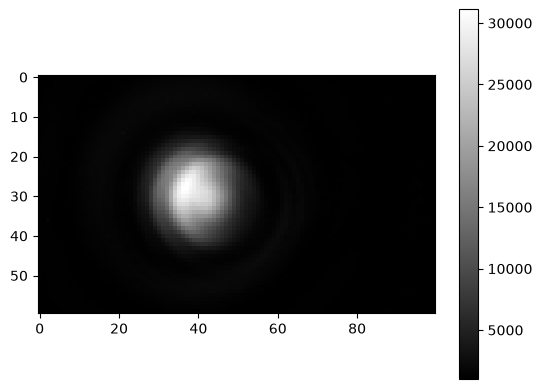

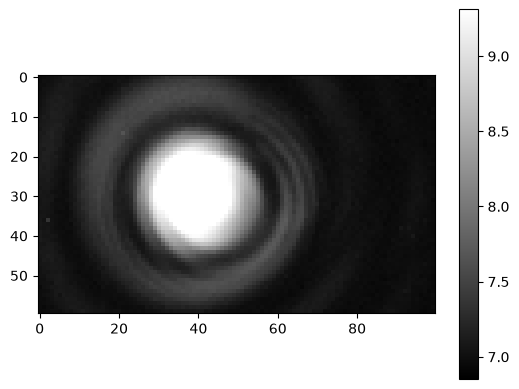

In [49]:
# try 1st w/ [a: position 3, 5mm] [ img_obs1_star1_a ]

plt.figure()#figsize=(12,9))
plt.imshow(img_obs1_star1_a[200:260,400:500], cmap='gray')
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

plt.figure()#figsize=(12,9))
plt.imshow(np.log(img_obs1_star1_a[200:260,400:500]), cmap='gray', vmax=np.max(np.log(img_obs1_star1_a[200:260,400:500]))*90/100,
          vmin=np.min(np.log(img_obs1_star1_a[200:260,400:500]))*99/100)
# add in to show WCS coords, etc
plt.colorbar();
#plt.title()

### Determining equivalent Stellar Magnitude

In [12]:
# want counts [~ number of photons] from part a
    # told quantum efficiency = 50% => assume *real* photon amount = twice photon count
    # 1) A "zero magnitude star" => 170 photons/msec over 5mm diameter aperture in the V-band (550±100nm)
    # 2) Observing band we used is different, only used 5mm aperture for 1 image [so may not be able to do for 1mm & 3mm diameters?], 
        # & need to normalise over the exposure time [used 30 secs for each image]

print(f'Expect to get ~ {170*1e3*30} photons per 30 sec over 5mm aperture in the V-band') # 170 photons/millisec to per 30 sec

# normally, for apparent magnitudes: m1 - m_ref = -2.5*log10(F1/F_ref) 
    # could take F as the photon counts here, *BUT* difference in spectral bands -> 
        # only took these images in *R filter* => convert m_v to m_r, then work as if data~r-band
            # transmission function? => check manual/supervisor


Expect to get ~ 5100000.0 photons per 30 sec over 5mm aperture in the V-band


## Task 2.3

- Aperture mask set to position 4 / 2 appertures, each of 1mm-diameter, with baseline separation = 5mm
    - Airy disk in images should now look like Fig12b [*fringes*] / Fig5 of manual
    - Images taken with spectral filters: B, C, G, R
- __Compute__ the <u>theoretical value</u> for the <u>fringe spacing</u> ("as discussed in Sect. 6.2")
    - fringe spacing $ = \frac{\lambda}{B}$
        - "Notation for the fringe spacing in milli arcsec (mas): $α/mas = 206 \frac{λ/μm}{B/m}$, with λ in μm"
- __Measure__ the <u>fringe spacing</u> __by__ noting the pixel coords of the cursor [SAO Image DS9]

### Measurement from Data

In [13]:
# record the fringe spacing via the pixel coords, then convert to [milli] arcsecs as before
    # could take a few measurements [of r], & then take the mean?
    # have r = sqrt( (x2-x1)^2 + (y2-y1)^2 )
        # & err_r = 
    # "1.77 arcsec/pixel" => 

# spectral filters B, C, G, R



### Computation from Theory

In [14]:
# fringe spacing = lambda / Baseline B => alpha [milli arcsec] = 206* lambda[mu m] / B [m]
    # lambda = in [mu m]
    # Baseline B = 5mm = 0.5cm = 0.005m
206*lamp_lambda/0.005 # milli arc sec

# can also get uncertainty using error propagation, as have uncertainty in lambda [better comparison w/image data]


25956.0

## Task 2.4

- Aperture mask set to position 4 / 2 appertures, each of 1mm-diameter, with baseline separation = 5mm
    - Airy disk in images should now look like Fig12b [*fringes*] / Fig5 of manual
    - Images taken with spectral filters: B, C, G, R
- __How many fringes__ do you *see* in <u>total</u>?
    - __Compare__ to the *theoretical value*  given by the <u>spectral bandwidth</u> ("see Sect. 4")
        - expect ~ $\frac{2\lambda}{\Delta \lambda}$ fringes, where (if I'm reading manual right) if told spectral band = $x \pm \Delta x$ nm, then $\lambda = x$ & $\Delta \lambda = 2 \times \Delta x$

### Measurement from Data

In [15]:
# spectral filters B, C, G, R

# how many *fringes* do you see in total? 



### Computation from Theory

In [16]:
# total fringes = ~ 2*lambda/delta_lambda, where delta_lambda = 2*uncertainty_lambda
            #   = lambda/err_lamda
lamp_lambda/err_lamp_lambda

12.6

# Also Sections 10.1 "Geometrical Constellation" [Tasks 1.1 & 1.2] AND 10.3 "Visibility Measurements" [Task 3.(1-5)] AND 10.4 "Data Analysis" [4.1 & 4.2]